# Step 6: Euclidean Alignment (Stage A)

**Research question, part 1:** can Euclidean Alignment (EA) make our EEGNet pipeline work better for a **person it has never seen** (cross-subject), and does it also help **the same person on another day** (session T → session E)?

**What EA does** (He & Wu, IEEE TBME 2020; evaluated with deep learning by Junqueira et al., 2024). For each group of trials (one subject's session):

$$R = \frac{1}{n}\sum_{i=1}^{n} \frac{X_i X_i^\top}{T}, \qquad \tilde X_i = R^{-1/2} X_i$$

After this, the group's average spatial covariance is the identity matrix, so every person's data is "centred" the same way before it reaches EEGNet. **EA uses no labels**, so a new user's reference can be computed from unlabelled EEG.

| Setting | Training data | Test data | How the test data is aligned |
|---|---|---|---|
| **Within-subject** | subject's 288 T trials (aligned with R of T) | same subject's 288 E trials | **offline**: R from all E trials; **pseudo-online**: R from the first 24 or 48 E trials only |
| **Cross-subject (LOSO)** | 8 other subjects, T + E (each session aligned with its own R) | unseen subject's E session | offline, or first 24 / 48 trials |

**Rules (same as notebooks 04–05):** pipeline option A (8–30 Hz, 0–4 s), the epoch count and early stopping come from training data only, **no label of a test session or test subject is ever used**, and the pseudo-online scores leave out the calibration trials for **every** method so the comparison is fair. Code: `src/alignment.py`, `experiments/run_ea.py`; this notebook only reads saved results (no training).

In [1]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import alignment as ea
from data import CLASS_NAMES, SUBJECTS
from plots import per_class_recall, plot_confusion_grid, plot_recall_heatmap
from preprocess import load_config_data

R = ROOT / "results" / "ea"
FIG = ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
J = lambda p: json.loads(Path(p).read_text())
summary = J(R / "summary.json")
T = summary["tables"]
within = [J(f) for f in sorted((R / "within_t2e").glob("*.json"))]
loso = {v: [J(f) for f in sorted((R / "loso" / v).glob("*.json"))] for v in ("NOEA", "EA")}
print("Overnight run status:", (ROOT / "results" / "overnight_status_ea.txt").read_text().strip().splitlines()[-1])
print(f"Runs loaded: {len(within)} within-subject (9 subjects x 5 seeds), "
      f"{len(loso['NOEA'])} + {len(loso['EA'])} cross-subject (9 subjects x 3 seeds, no EA / EA)")

Overnight run status: [2026-10-15 04:40:07] ALL DONE - results in results/ea/summary.md
Runs loaded: 45 within-subject (9 subjects x 5 seeds), 27 + 27 cross-subject (9 subjects x 3 seeds, no EA / EA)


## 1. Implementation checks
`tests/test_alignment.py` checks the maths on real data: R<sup>−1/2</sup> is correct and symmetric, every one of the 18 recordings has identity mean covariance after EA, no labels are used and trial order does not matter, and the pseudo-online reference (first 48 trials) is close to the offline one.

In [2]:
out = subprocess.run([sys.executable, str(ROOT / "tests" / "test_alignment.py")], capture_output=True, text=True, cwd=str(ROOT))
print("\n".join(l for l in out.stdout.splitlines() if l.startswith(("ok", "ALL"))))

ok  R^(-1/2) R R^(-1/2) = I and R^(-1/2) is symmetric
ok  all 18 recordings: mean covariance after EA = identity (max deviation 9.1e-10)
ok  EA uses no labels and does not depend on trial order; shape preserved (288, 22, 1000)
ok  mean pairwise distance between subjects' mean covariances: 0.1391 before EA -> 0.0000 after (zero by construction: every subject is centred on the identity; individual trials still differ)
ok  pseudo-online reference (first 48 trials) differs from offline reference by 7.7%
ALL TESTS PASSED


## 2. What EA does to the data: mean covariance per subject, before and after
Top row: each subject's average spatial covariance on session T (trace-normalised so the subjects can share one colour scale). Bottom row: the same after EA. Before EA every person has a different "fingerprint" (which channels have high power and how they co-vary); after EA all of them become the identity matrix.

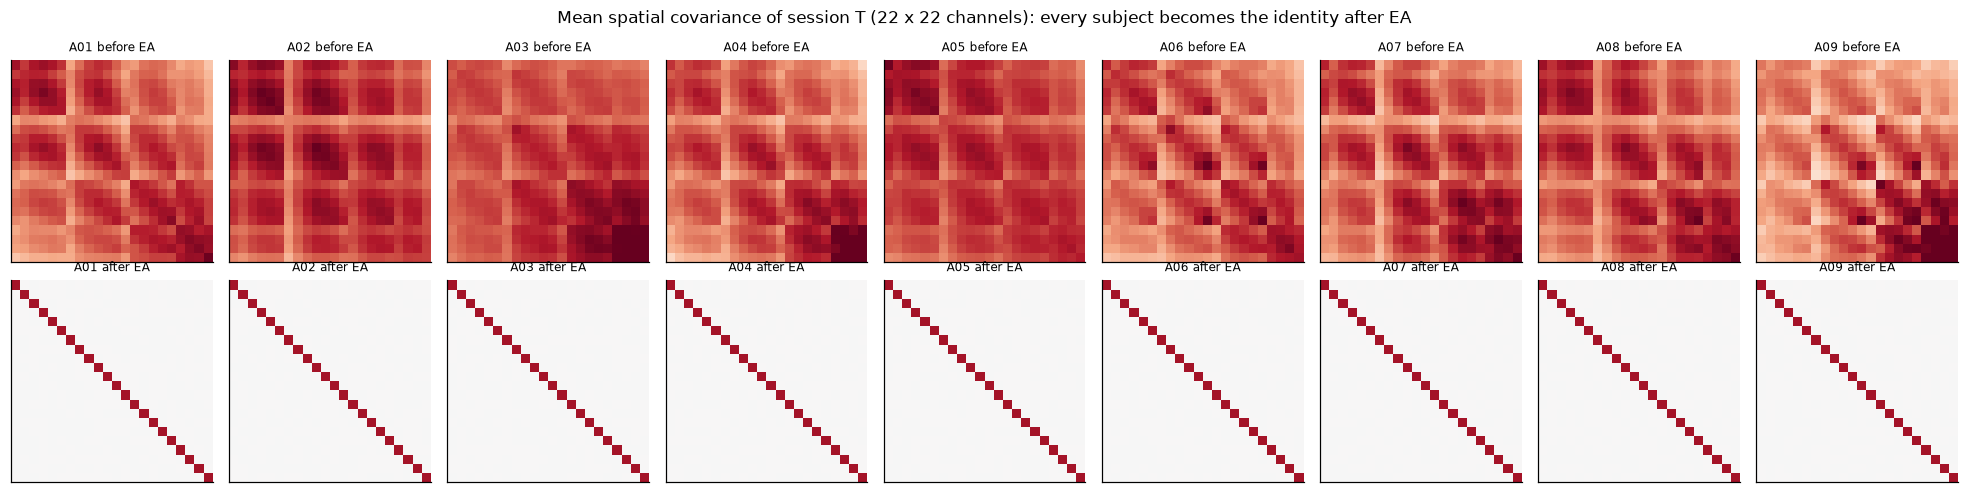

Mean |off-diagonal| covariance (trace-normalised): before EA 0.733, after EA 5.4e-11


In [3]:
covs_before, covs_after = {}, {}
for s in SUBJECTS:
    X, _ = load_config_data("A", s, "T")
    C = ea.reference_covariance(X); covs_before[s] = C / np.trace(C) * 22
    covs_after[s] = ea.reference_covariance(ea.align_self(X)[0])
vmax = np.percentile(np.abs(np.stack(list(covs_before.values()))), 99)
fig, axes = plt.subplots(2, 9, figsize=(18, 4.6))
for j, s in enumerate(SUBJECTS):
    for i, (C, lab) in enumerate([(covs_before[s], "before EA"), (covs_after[s], "after EA")]):
        ax = axes[i, j]; ax.imshow(C, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{s} {lab}", fontsize=8)
fig.suptitle("Mean spatial covariance of session T (22 x 22 channels): every subject becomes the identity after EA", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "06_covariance_before_after.png", bbox_inches="tight"); plt.show()

off = lambda C: np.abs(C - np.diag(np.diag(C))).mean()
print("Mean |off-diagonal| covariance (trace-normalised):",
      f"before EA {np.mean([off(c) for c in covs_before.values()]):.3f}, after EA {np.mean([off(c) for c in covs_after.values()]):.1e}")

**Reading:** EA removes the person-specific (and session-specific) shape of the covariance. The trials themselves still differ, which is where the motor-imagery information is, but every subject now starts from the same reference point. That is why a model trained on 8 people transfers better to a 9th.

## 3. Cross-subject (new user): the main result
Trained on 8 subjects (T + E), tested on the unseen subject's E session. Same budget for both versions (up to 600 epochs, early stopping with patience 80 on 20% of the training subjects' trials), 3 seeds each. *Single* = mean over the 3 seeds; *ensemble* = the 3 seeds' probabilities averaged.

In [4]:
def row(name, key):
    t = T[key]
    return [{"setting": name, "type": kind, **{s: round(100 * t[kind][s], 1) for s in SUBJECTS},
             "mean": round(100 * t[kind]["mean"], 2)} for kind in ("single", "ensemble")]

cross_rows = (row("No EA", "loso_noEA") + row("EA, offline (all target trials)", "loso_EA_offline")
              + row("No EA, scored from trial 49", "loso_noEA_from48") + row("EA, pseudo-online (first 48 trials)", "loso_EA_online48")
              + row("No EA, scored from trial 25", "loso_noEA_from24") + row("EA, pseudo-online (first 24 trials)", "loso_EA_online24"))
cross = pd.DataFrame(cross_rows)
cross

,setting,type,A01,A02,A03,A04,A05,A06,A07,A08,A09,mean
0,No EA,single,62.0,28.9,64.9,32.6,27.4,28.7,30.8,66.6,58.0,44.44
1,No EA,ensemble,66.3,29.2,70.1,31.6,26.0,27.1,31.6,67.7,60.8,45.60
2,"EA, offline (all target trials)",single,70.0,32.2,76.5,44.8,35.3,43.5,39.0,68.5,65.9,52.85
3,"EA, offline (all target trials)",ensemble,71.2,34.0,79.2,46.2,35.4,47.9,40.3,72.6,64.9,54.63
4,"No EA, scored from trial 49",single,60.8,29.3,66.2,33.3,27.5,27.2,30.4,66.0,55.0,43.98
5,"No EA, scored from trial 49",ensemble,65.4,29.6,70.4,32.5,25.8,25.8,31.2,65.8,57.9,44.95
6,"EA, pseudo-online (first 48 trials)",single,68.6,32.2,73.5,40.4,33.8,38.6,39.7,65.3,62.8,50.54
7,"EA, pseudo-online (first 48 trials)",ensemble,75.0,35.0,72.9,40.4,34.2,40.4,42.1,68.3,64.2,52.50
8,"No EA, scored from trial 25",single,61.4,28.4,65.2,32.8,26.8,27.9,30.2,66.0,55.9,43.84
9,"No EA, scored from trial 25",ensemble,65.5,28.8,69.7,31.8,25.4,26.5,31.1,66.7,58.3,44.87


In [5]:
tests = pd.DataFrame(summary["tests"]).T.rename(columns={"mean_diff_pp": "gain (pp)", "wilcoxon_p": "Wilcoxon p (9 subjects)"})
tests["gain (pp)"] = tests["gain (pp)"].round(2); tests["Wilcoxon p (9 subjects)"] = tests["Wilcoxon p (9 subjects)"].round(3)
tests["EA better for"] = [sum(T[a.split(" vs ")[0]]["single"][s] > T[a.split(" vs ")[1]]["single"][s] for s in SUBJECTS) for a in tests.index]
tests["EA better for"] = tests["EA better for"].astype(str) + " / 9 subjects"
tests

,gain (pp),Wilcoxon p (9 subjects),EA better for
loso_EA_offline vs loso_noEA,8.41,0.004,9 / 9 subjects
loso_EA_online48 vs loso_noEA_from48,6.56,0.008,8 / 9 subjects
loso_EA_online24 vs loso_noEA_from24,6.05,0.004,9 / 9 subjects
within_EA_offline vs within_noEA,3.19,0.156,7 / 9 subjects
within_EA_online48 vs within_noEA_from48,1.65,0.652,5 / 9 subjects


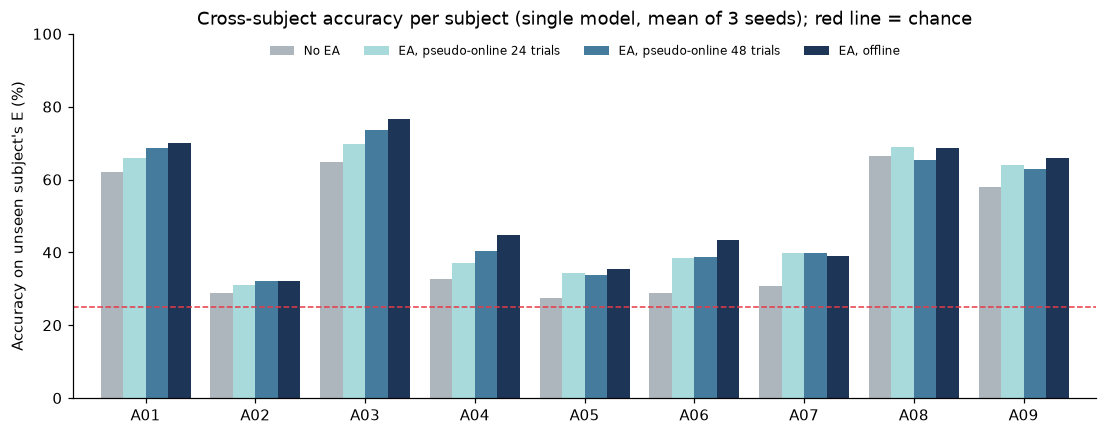

In [6]:
plot = pd.DataFrame({"No EA": [T["loso_noEA"]["single"][s] for s in SUBJECTS],
                     "EA, pseudo-online 24 trials": [T["loso_EA_online24"]["single"][s] for s in SUBJECTS],
                     "EA, pseudo-online 48 trials": [T["loso_EA_online48"]["single"][s] for s in SUBJECTS],
                     "EA, offline": [T["loso_EA_offline"]["single"][s] for s in SUBJECTS]}, index=SUBJECTS) * 100
ax = plot.plot.bar(figsize=(12, 4.3), color=["#adb5bd", "#a8dadc", "#457b9d", "#1d3557"], rot=0, width=0.82)
ax.axhline(25, color="#e63946", ls="--", lw=1); ax.set_ylim(0, 100); ax.set_ylabel("Accuracy on unseen subject's E (%)")
ax.set_title("Cross-subject accuracy per subject (single model, mean of 3 seeds); red line = chance")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
ax.figure.savefig(FIG / "06_loso_per_subject.png", bbox_inches="tight"); plt.show()

**Reading:** EA improves cross-subject accuracy from **44.44% to 52.85%** (+8.4 points, Wilcoxon p = 0.004), and **every subject improves**. It still works when the new user only provides a short unlabelled calibration block: +6.6 points with 48 trials and +6.1 with 24 trials (about 2–4 minutes of EEG). The largest gains are for subjects the plain model could hardly decode, such as A06 (28.7 → 43.5%) and A04 (32.6 → 44.8%). Junqueira et al. reported +4.33 points from EA (2 classes); we see the same direction and a larger effect with 4 classes.

## 4. Training speed: EA converges faster
The early-stopping epoch (lowest validation loss on the training subjects) is a measure of how long the model needs. The right panel shows accuracy on the unseen subject during training. It is **recorded for plotting only**: it never influences early stopping or the chosen model.

         best epoch  epochs run
variant                        
EA            272.4       352.4
NOEA          476.4       539.3


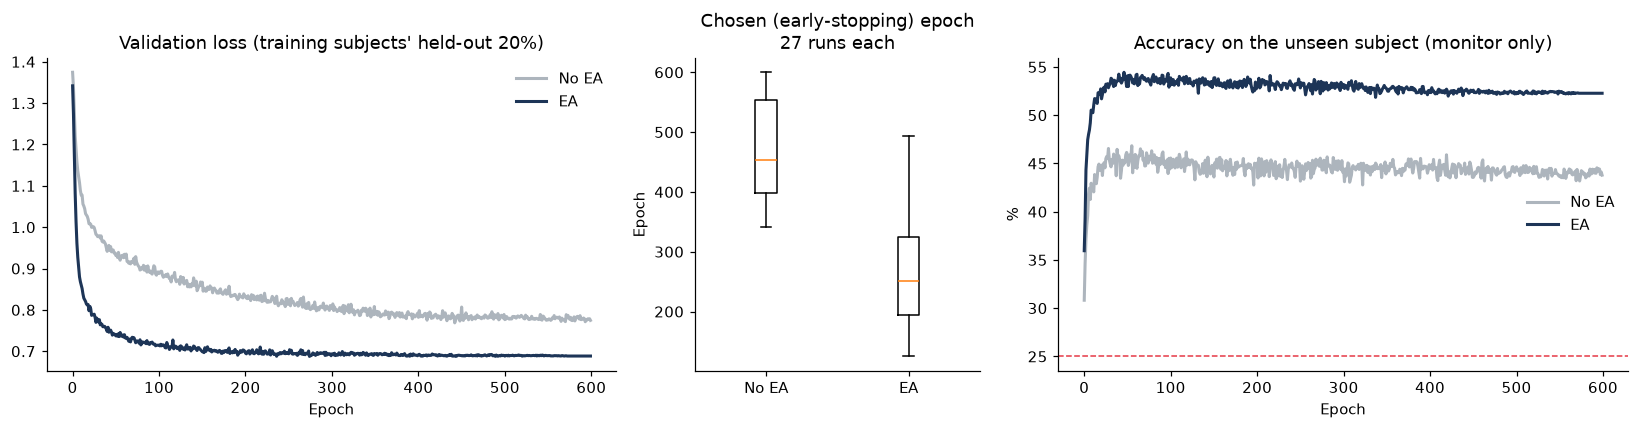

In [7]:
be = pd.DataFrame([{"variant": v, "subject": r["subject"], "seed": r["seed"], "best epoch": r["best_epoch"], "epochs run": r["epochs_run"]}
                   for v in loso for r in loso[v]])
print(be.groupby("variant")[["best epoch", "epochs run"]].mean().round(1))

def mean_curve(runs, key, n=600):
    M = np.full((len(runs), n), np.nan)
    for i, r in enumerate(runs):
        c = np.array(r["history"][key]); M[i, :len(c)] = c; M[i, len(c):] = c[-1]   # hold last value after stopping
    return np.nanmean(M, 0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1, 2]})
for v, col in [("NOEA", "#adb5bd"), ("EA", "#1d3557")]:
    axes[0].plot(mean_curve(loso[v], "val_loss"), color=col, lw=2, label=f"{'No EA' if v == 'NOEA' else 'EA'}")
    axes[2].plot(100 * mean_curve(loso[v], "target_acc_monitor"), color=col, lw=2, label=f"{'No EA' if v == 'NOEA' else 'EA'}")
axes[0].set_title("Validation loss (training subjects' held-out 20%)"); axes[0].set_xlabel("Epoch"); axes[0].legend(frameon=False)
axes[1].boxplot([be[be.variant == v]["best epoch"] for v in ("NOEA", "EA")], tick_labels=["No EA", "EA"])
axes[1].set_title("Chosen (early-stopping) epoch\n27 runs each"); axes[1].set_ylabel("Epoch")
axes[2].axhline(25, color="#e63946", ls="--", lw=1)
axes[2].set_title("Accuracy on the unseen subject (monitor only)"); axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("%"); axes[2].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "06_loso_convergence.png", bbox_inches="tight"); plt.show()

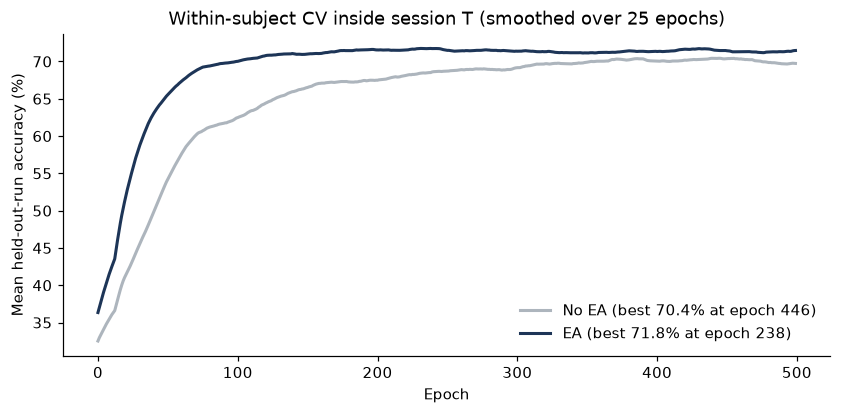

In [8]:
# within-subject: CV curve inside session T (EA vs our no-EA BASE from notebook 05), 9 subjects x 6 folds
def cv_curve(folder):
    runs = [J(folder / f"{s}_run{r}.json") for s in SUBJECTS for r in range(1, 7)]
    c = 100 * np.mean([x["mon_acc"] for x in runs], 0)
    return np.array([c[max(0, i - 12): i + 13].mean() for i in range(len(c))])
sel = J(R / "within_selection.json")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(cv_curve(ROOT / "results" / "mentor" / "eeg_cv" / "BASE"), color="#adb5bd", lw=2,
        label=f"No EA (best {100 * sel['base_cv']['cv_acc']:.1f}% at epoch {sel['base_cv']['best_epochs']})")
ax.plot(cv_curve(R / "within_cv"), color="#1d3557", lw=2, label=f"EA (best {100 * sel['cv_acc']:.1f}% at epoch {sel['best_epochs']})")
ax.set_xlabel("Epoch"); ax.set_ylabel("Mean held-out-run accuracy (%)")
ax.set_title("Within-subject CV inside session T (smoothed over 25 epochs)"); ax.legend(frameon=False, loc="lower right")
fig.savefig(FIG / "06_within_cv_curves.png", bbox_inches="tight"); plt.show()

**Reading:** cross-subject, EA reaches its best model at about **272 epochs instead of 476** (≈43% fewer), and its accuracy on the unseen subject rises faster and stays about 8 points higher throughout training. Within-subject, EA reaches its best T-session CV accuracy (71.8%) at epoch 238 instead of 446 (70.4%). This matches Junqueira et al., who reported faster convergence with EA.

One honest observation: accuracy on the unseen subject peaks early (around epoch 50) and then drifts down slightly, while early stopping on the *training* subjects picks a later epoch. We cannot use the unseen subject's curve to choose the epoch (that would need its labels), so this is a cost of the domain shift that we accept.

## 5. Does EA fix the "stuck on one class" problem?
In notebook 03/04 the cross-subject model predicted almost only one class for some people (A05: "left hand" for most trials), which on a wheelchair would mean always turning the same way. Below: the share of predictions that go to the single most-predicted class (25% = balanced, 100% = completely stuck), and the confusion matrices of the 3-seed ensemble.

In [9]:
def ens_pred(runs, ref):
    by = {}
    for r in runs:
        by.setdefault(r["subject"], []).append(np.array(r["probs"][ref]))
    y = {r["subject"]: np.array(r["y"]) for r in runs}
    return y, {s: np.mean(by[s], 0).argmax(1) for s in SUBJECTS}
y_true, pred_no = ens_pred(loso["NOEA"], "none")
_, pred_ea = ens_pred(loso["EA"], "offline")
dom = lambda p: 100 * np.bincount(p, minlength=4).max() / len(p)
top = lambda p: CLASS_NAMES[np.bincount(p, minlength=4).argmax()]
collapse = pd.DataFrame({"No EA: most-predicted class": {s: top(pred_no[s]) for s in SUBJECTS},
                         "No EA: share (%)": {s: round(dom(pred_no[s]), 1) for s in SUBJECTS},
                         "EA: most-predicted class": {s: top(pred_ea[s]) for s in SUBJECTS},
                         "EA: share (%)": {s: round(dom(pred_ea[s]), 1) for s in SUBJECTS}})
collapse

,No EA: most-predicted class,No EA: share (%),EA: most-predicted class,EA: share (%)
A01,left_hand,37.2,tongue,38.2
A02,right_hand,64.2,left_hand,40.6
A03,tongue,46.2,right_hand,34.4
A04,right_hand,70.1,tongue,39.2
A05,left_hand,94.1,right_hand,70.5
A06,tongue,67.0,tongue,28.1
A07,feet,51.0,left_hand,32.6
A08,right_hand,34.4,feet,30.6
A09,tongue,44.1,right_hand,29.9


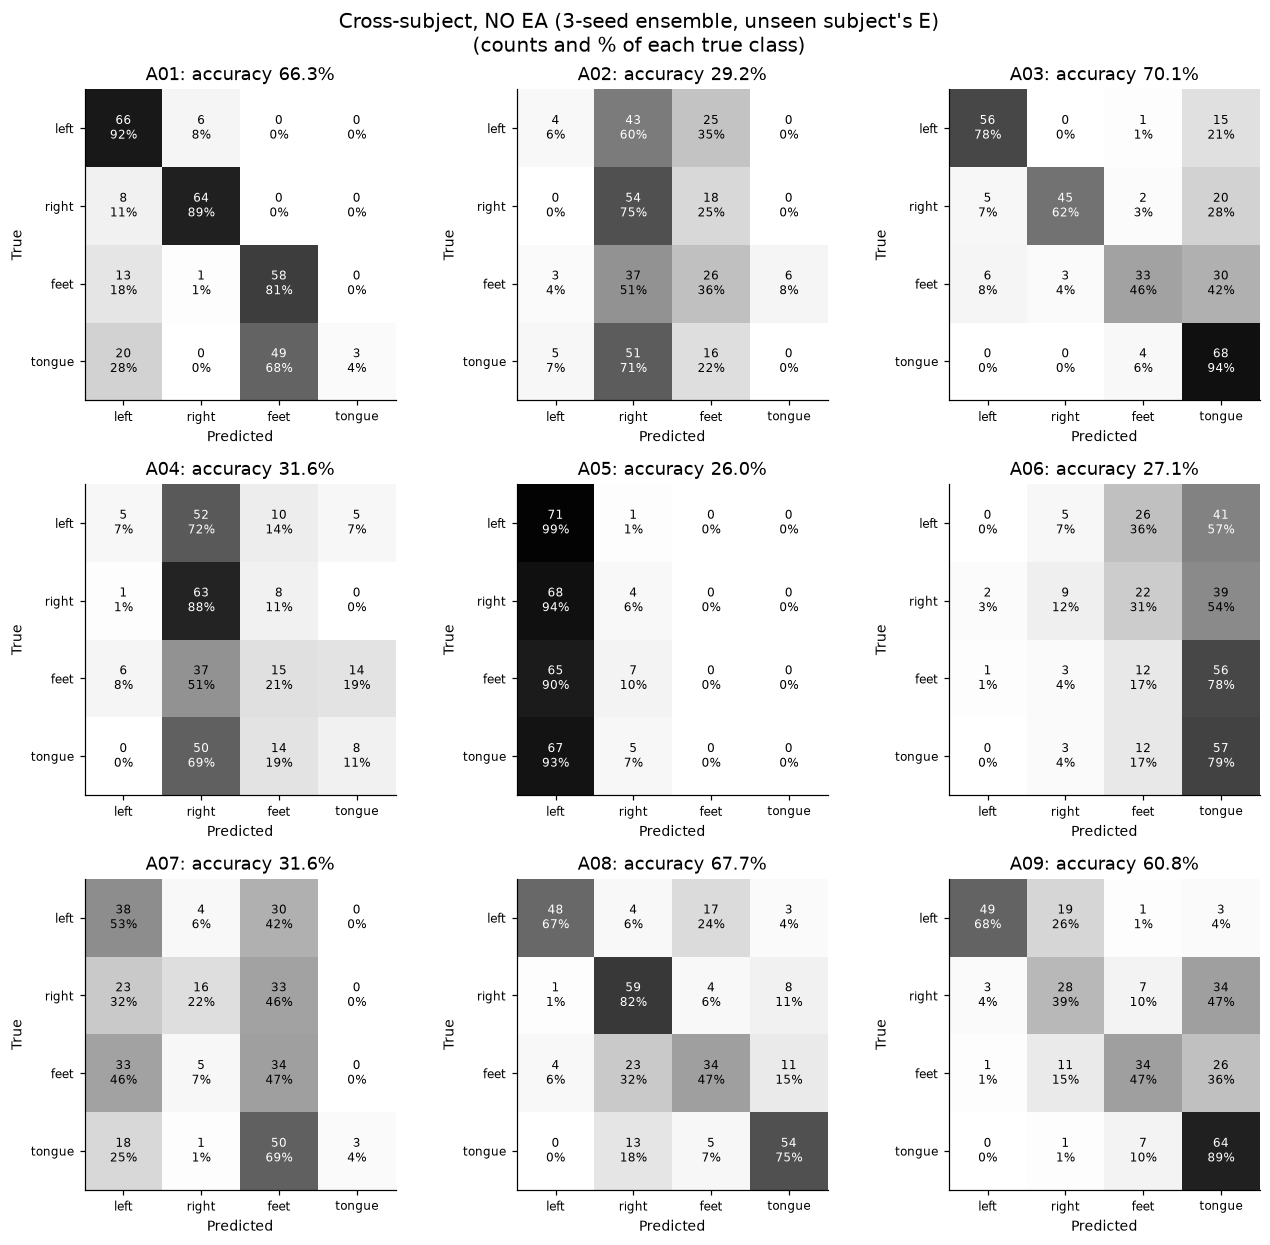

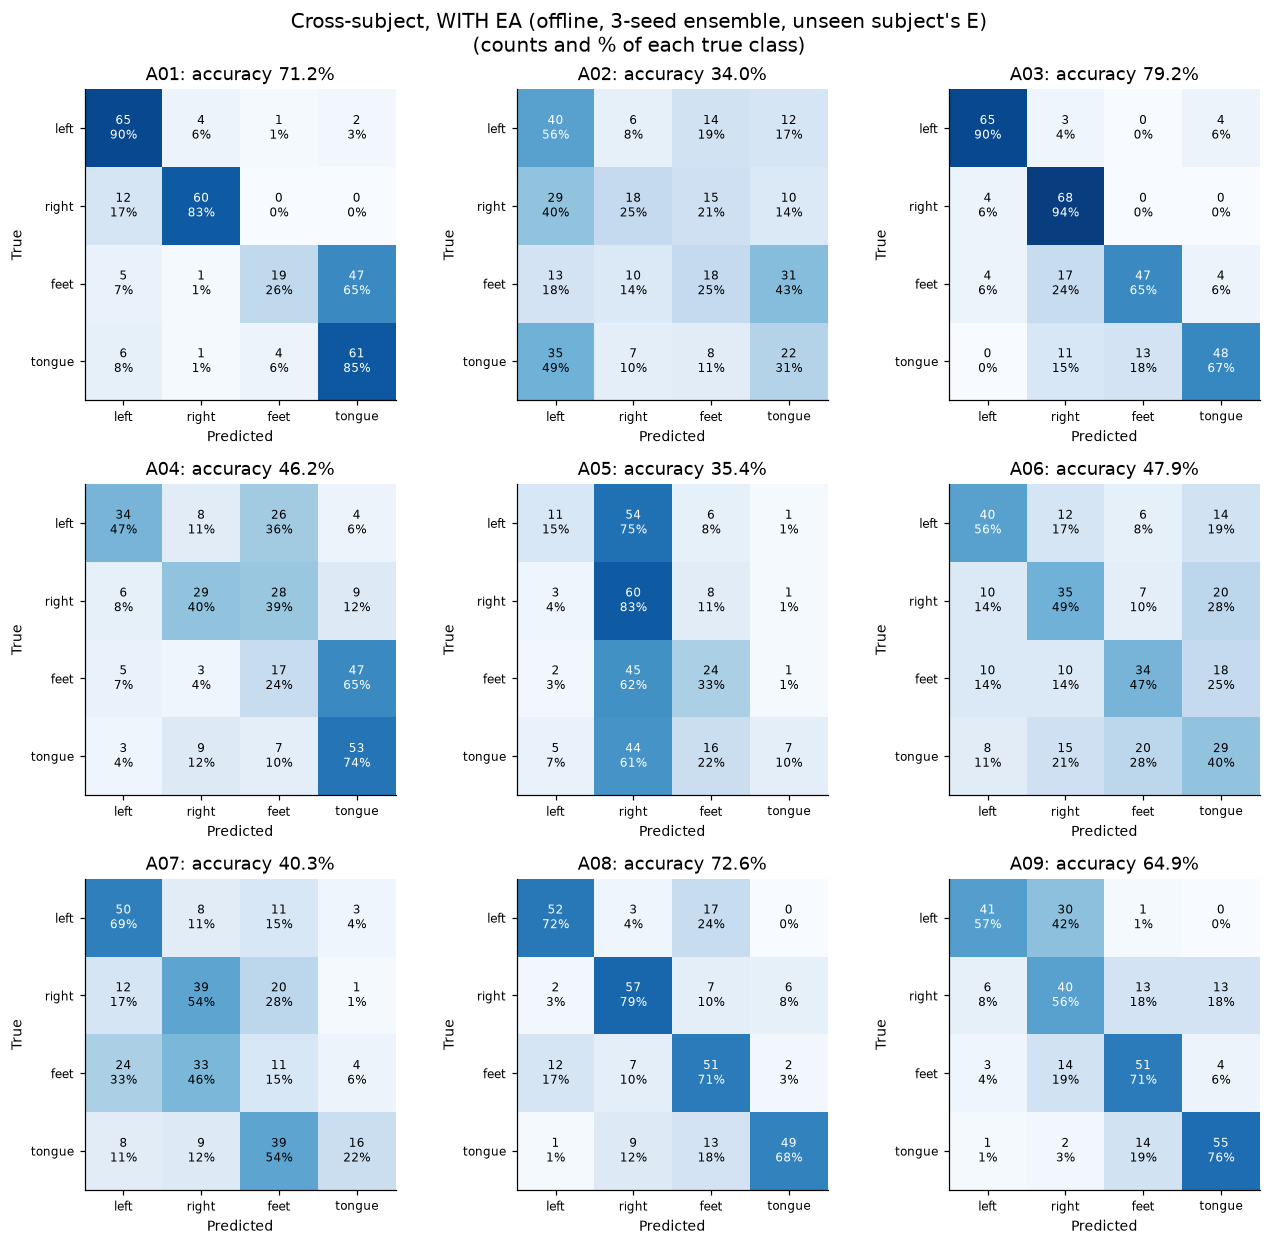

No EA                                EA                        
     left_hand right_hand  feet tongue left_hand right_hand  feet tongue
A01       91.7       88.9  80.6    4.2      90.3       83.3  26.4   84.7
A02        5.6       75.0  36.1    0.0      55.6       25.0  25.0   30.6
A03       77.8       62.5  45.8   94.4      90.3       94.4  65.3   66.7
A04        6.9       87.5  20.8   11.1      47.2       40.3  23.6   73.6
A05       98.6        5.6   0.0    0.0      15.3       83.3  33.3    9.7
A06        0.0       12.5  16.7   79.2      55.6       48.6  47.2   40.3
A07       52.8       22.2  47.2    4.2      69.4       54.2  15.3   22.2
A08       66.7       81.9  47.2   75.0      72.2       79.2  70.8   68.1
A09       68.1       38.9  47.2   88.9      56.9       55.6  70.8   76.4
mean      52.0       52.8  38.0   39.7      61.4       62.7  42.0   52.5

In [10]:
plot_confusion_grid(y_true, pred_no, CLASS_NAMES, "Cross-subject, NO EA (3-seed ensemble, unseen subject's E)", "Greys",
                    FIG / "06_loso_confusion_noEA.png"); plt.show()
plot_confusion_grid(y_true, pred_ea, CLASS_NAMES, "Cross-subject, WITH EA (offline, 3-seed ensemble, unseen subject's E)", "Blues",
                    FIG / "06_loso_confusion_EA.png"); plt.show()
rec = pd.concat({"No EA": per_class_recall(y_true, pred_no, CLASS_NAMES), "EA": per_class_recall(y_true, pred_ea, CLASS_NAMES)}, axis=1)
rec.round(1)

**Reading:** without EA, four unseen subjects were heavily stuck on one class: **A05 94.1%** "left hand", A04 70.1% "right hand", A06 67.0% "tongue", A02 64.2% "right hand". With EA, A02, A04 and A06 become close to balanced (28–41%), and the mean recall of every class rises (e.g. tongue 39.7 → 52.5%). **A05 is still stuck**, now on "right hand" (70.5%): EA moves the bias but does not remove it for this subject. On a wheelchair that user would still get many wrong RIGHT commands, which is exactly why the next stage, rejecting uncertain commands, is needed.

## 6. Within-subject (same person, another day)
Each subject's model is trained on its T session (aligned with R<sub>T</sub>) and tested on its E session (aligned with R<sub>E</sub>). The epoch count (238) was chosen by CV inside T. 5 seeds; *ensemble* = the 5 seeds' probabilities averaged, which is our **final system** (EA + 5-model ensemble). The no-EA rows are notebook 04's runs (446 epochs).

In [11]:
within_rows = (row("No EA (notebook 04)", "within_noEA") + row("EA, offline (all E trials)", "within_EA_offline")
               + row("No EA, scored from trial 49", "within_noEA_from48") + row("EA, pseudo-online (first 48 E trials)", "within_EA_online48")
               + row("No EA, scored from trial 25", "within_noEA_from24") + row("EA, pseudo-online (first 24 E trials)", "within_EA_online24"))
wdf = pd.DataFrame(within_rows)
wdf

,setting,type,A01,A02,A03,A04,A05,A06,A07,A08,A09,mean
0,No EA (notebook 04),single,81.5,46.9,89.7,59.5,54.4,49.9,70.8,78.8,82.3,68.20
1,No EA (notebook 04),ensemble,87.2,48.6,92.7,67.4,61.8,60.8,78.5,80.2,84.7,73.53
2,"EA, offline (all E trials)",single,82.2,59.1,89.7,57.7,56.5,47.3,82.7,84.3,83.1,71.40
3,"EA, offline (all E trials)",ensemble,85.4,64.6,90.6,65.3,63.2,55.9,86.1,87.2,87.2,76.16
4,"No EA, scored from trial 49",single,81.7,45.1,89.5,59.8,54.3,47.5,69.8,78.1,82.0,67.53
5,"No EA, scored from trial 49",ensemble,88.3,46.7,92.9,68.3,62.1,57.5,77.5,79.2,85.4,73.10
6,"EA, pseudo-online (first 48 E trials)",single,79.7,56.6,84.9,56.2,55.9,44.5,79.4,83.2,82.2,69.18
7,"EA, pseudo-online (first 48 E trials)",ensemble,82.5,61.3,86.2,60.4,62.9,52.5,81.2,85.8,84.6,73.06
8,"No EA, scored from trial 25",single,81.2,46.8,89.6,60.3,53.9,48.1,70.0,78.7,82.3,67.89
9,"No EA, scored from trial 25",ensemble,87.1,48.5,92.8,68.2,61.4,58.7,77.7,80.3,85.6,73.36


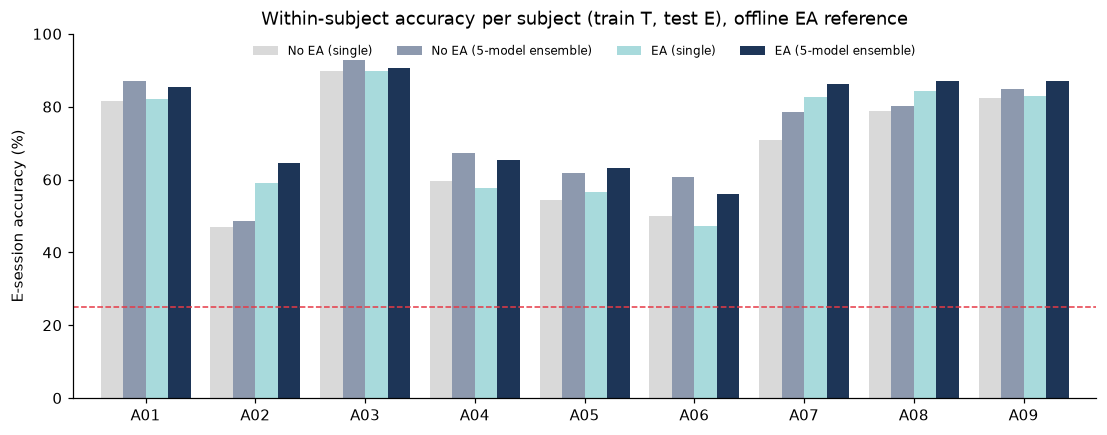

In [12]:
plot = pd.DataFrame({"No EA (single)": [T["within_noEA"]["single"][s] for s in SUBJECTS],
                     "No EA (5-model ensemble)": [T["within_noEA"]["ensemble"][s] for s in SUBJECTS],
                     "EA (single)": [T["within_EA_offline"]["single"][s] for s in SUBJECTS],
                     "EA (5-model ensemble)": [T["within_EA_offline"]["ensemble"][s] for s in SUBJECTS]}, index=SUBJECTS) * 100
ax = plot.plot.bar(figsize=(12, 4.3), color=["#d9d9d9", "#8d99ae", "#a8dadc", "#1d3557"], rot=0, width=0.82)
ax.axhline(25, color="#e63946", ls="--", lw=1); ax.set_ylim(0, 100); ax.set_ylabel("E-session accuracy (%)")
ax.set_title("Within-subject accuracy per subject (train T, test E), offline EA reference")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
ax.figure.savefig(FIG / "06_within_per_subject.png", bbox_inches="tight"); plt.show()

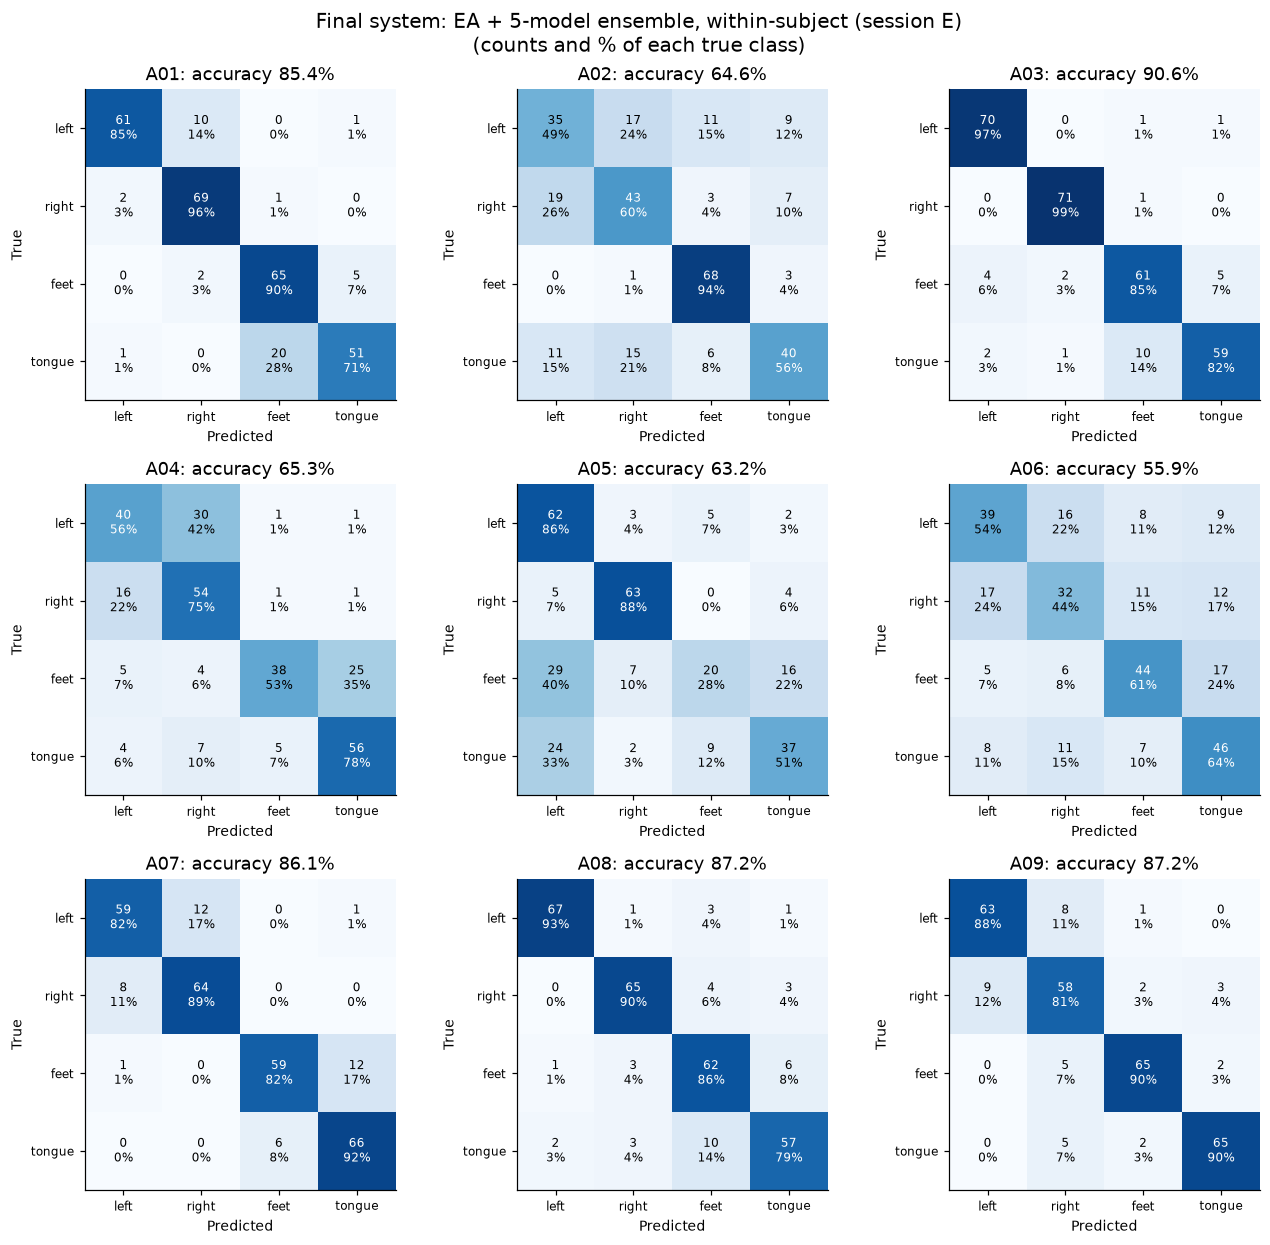

In [13]:
y_w, pred_w = ens_pred(within, "offline")
plot_confusion_grid(y_w, pred_w, CLASS_NAMES, "Final system: EA + 5-model ensemble, within-subject (session E)", "Blues",
                    FIG / "06_within_confusion_final.png"); plt.show()

**Reading:** EA also helps the same person across days: **68.20 → 71.40%** for one model and **73.53 → 76.16%** for the 5-model ensemble, above the 15-network ensemble of Nzakuna et al. (EMCD, 75.35%). The single-model gain is **not statistically significant** (p = 0.16), because it is large for some subjects (A02 +12.2, A07 +11.9, A08 +5.5) and slightly negative for others (A04, A06). With only the first 48 E trials as reference the gain shrinks (67.53 → 69.18% single, 73.10 → 73.06% ensemble), so the 76.16% depends on aligning with the whole unlabelled E session.

## 7. Offline vs pseudo-online alignment: how many calibration trials does a new user need?

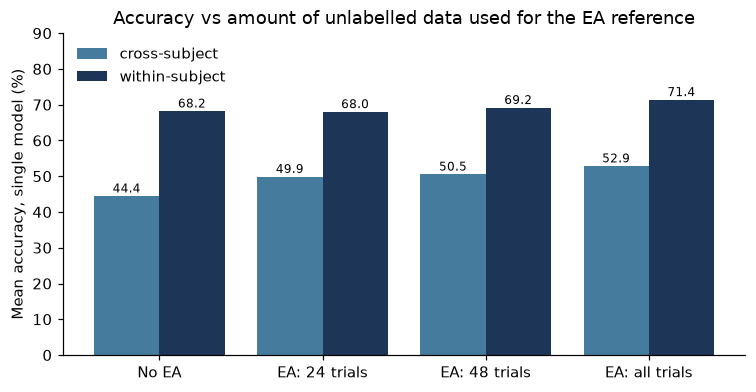

In [14]:
labels = ["No EA", "EA: 24 trials", "EA: 48 trials", "EA: all trials"]
cross_v = [T["loso_noEA"]["single"]["mean"], T["loso_EA_online24"]["single"]["mean"], T["loso_EA_online48"]["single"]["mean"], T["loso_EA_offline"]["single"]["mean"]]
within_v = [T["within_noEA"]["single"]["mean"], T["within_EA_online24"]["single"]["mean"], T["within_EA_online48"]["single"]["mean"], T["within_EA_offline"]["single"]["mean"]]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(4)
ax.bar(x - 0.2, 100 * np.array(cross_v), 0.4, color="#457b9d", label="cross-subject")
ax.bar(x + 0.2, 100 * np.array(within_v), 0.4, color="#1d3557", label="within-subject")
for i in range(4):
    ax.text(i - 0.2, 100 * cross_v[i] + 1, f"{100 * cross_v[i]:.1f}", ha="center", fontsize=8)
    ax.text(i + 0.2, 100 * within_v[i] + 1, f"{100 * within_v[i]:.1f}", ha="center", fontsize=8)
ax.set_xticks(x, labels); ax.set_ylim(0, 90); ax.set_ylabel("Mean accuracy, single model (%)")
ax.set_title("Accuracy vs amount of unlabelled data used for the EA reference")
ax.legend(frameon=False); fig.savefig(FIG / "06_offline_vs_online.png", bbox_inches="tight"); plt.show()

**Reading:** for a **new user**, even 24 unlabelled trials (about 2 minutes) recover most of the EA gain (+6.1 of +8.4 points). For the **same user on another day**, the short reference is too noisy to help much; aligning with more of the session works better. A practical system could start with a short calibration block and update the reference as more trials arrive.

## 8. Extra check: EA combined with Mam's sparse classifier
Notebook 05 found that fusing her wavelet-energy sparse classifier with EEGNet improves one model (68.20 → 70.10%). EA and her classifier were each added separately, so here we combine them. The fusion weight (0.9) and the probability scale are the values **chosen on session T in notebook 05**; nothing is tuned on E. No training is needed: both models' E predictions are saved.

In [15]:
M = ROOT / "results" / "mentor"
sp_sel = J(M / "sparse_selection.json"); w = J(M / "summary.json")["fusion"]["weight"]; k = sp_sel["prob_scale"]
def sparse_probs(S):
    z = (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-9)
    p = np.exp(k * z - (k * z).max(1, keepdims=True)); return p / p.sum(1, keepdims=True)
sp = {s: sparse_probs(np.array(J(M / "sparse_t2e" / sp_sel["chosen"] / f"{s}.json")["scores"][sp_sel["rule"]])) for s in SUBJECTS}
acc = lambda y, sc: float((np.asarray(sc).argmax(1) == np.asarray(y)).mean())
out = []
for ref_name in ("offline", "online48"):
    by = {}
    for r in within:
        by.setdefault(r["subject"], []).append((np.array(r["y"]), np.array(r["probs"][ref_name])))
    start = 0 if ref_name == "offline" else 48
    for fuse in (False, True):
        ww = w if fuse else 0.0
        single = {s: np.mean([acc(y[start:], np.log(p[start:] + 1e-9) + ww * np.log(sp[s][start:] + 1e-9)) for y, p in by[s]]) for s in SUBJECTS}
        ens = {s: acc(by[s][0][0][start:], np.log(np.mean([p for _, p in by[s]], 0)[start:] + 1e-9) + ww * np.log(sp[s][start:] + 1e-9)) for s in SUBJECTS}
        for kind, d in (("single", single), ("ensemble", ens)):
            out.append({"EA reference": ref_name, "pipeline": "EA + her classifier" if fuse else "EA only", "type": kind,
                        **{s: round(100 * d[s], 1) for s in SUBJECTS}, "mean": round(100 * np.mean(list(d.values())), 2)})
fusion_ea = pd.DataFrame(out)
fusion_ea

,EA reference,pipeline,type,A01,A02,A03,A04,A05,A06,A07,A08,A09,mean
0,offline,EA only,single,82.2,59.1,89.7,57.7,56.5,47.3,82.7,84.3,83.1,71.40
1,offline,EA only,ensemble,85.4,64.6,90.6,65.3,63.2,55.9,86.1,87.2,87.2,76.16
2,offline,EA + her classifier,single,84.7,56.9,88.2,62.8,57.6,49.5,84.9,86.2,85.1,72.88
3,offline,EA + her classifier,ensemble,87.8,58.7,87.5,69.4,61.1,54.9,88.2,86.5,87.5,75.73
4,online48,EA only,single,79.7,56.6,84.9,56.2,55.9,44.5,79.4,83.2,82.2,69.18
5,online48,EA only,ensemble,82.5,61.3,86.2,60.4,62.9,52.5,81.2,85.8,84.6,73.06
6,online48,EA + her classifier,single,83.8,55.3,84.3,60.9,57.7,47.5,81.2,83.8,83.8,70.94
7,online48,EA + her classifier,ensemble,86.7,56.2,85.0,65.4,60.8,52.9,84.2,83.3,87.9,73.61


**Reading:** her classifier still adds information to **one** aligned EEGNet: **71.40 → 72.88%** (+1.5; offline) and 69.18 → 70.94% (+1.8; first 48 trials). But it does **not** improve the 5-model ensemble (76.16 → 75.73%; 73.06 → 73.61% with 48 trials). Averaging 5 networks already corrects most of the errors her classifier fixes. So our final system stays **EA + 5-model ensemble** (76.16%); EA + her classifier is the best **single-model** result (72.88%).

## 9. Summary of Stage A

In [16]:
final = pd.DataFrame([
    {"setting": "Within-subject (train T, test E)", "no EA, 1 model": T["within_noEA"]["single"]["mean"], "EA, 1 model": T["within_EA_offline"]["single"]["mean"],
     "no EA, ensemble": T["within_noEA"]["ensemble"]["mean"], "EA, ensemble": T["within_EA_offline"]["ensemble"]["mean"],
     "Wilcoxon p (1 model)": summary["tests"]["within_EA_offline vs within_noEA"]["wilcoxon_p"]},
    {"setting": "Cross-subject (unseen user)", "no EA, 1 model": T["loso_noEA"]["single"]["mean"], "EA, 1 model": T["loso_EA_offline"]["single"]["mean"],
     "no EA, ensemble": T["loso_noEA"]["ensemble"]["mean"], "EA, ensemble": T["loso_EA_offline"]["ensemble"]["mean"],
     "Wilcoxon p (1 model)": summary["tests"]["loso_EA_offline vs loso_noEA"]["wilcoxon_p"]}]).set_index("setting")
for c in final.columns[:4]:
    final[c] = (100 * final[c]).round(2)
final["Wilcoxon p (1 model)"] = final["Wilcoxon p (1 model)"].round(3)
final["gap within - cross (EA, ensemble)"] = ""
final.loc["Cross-subject (unseen user)", "gap within - cross (EA, ensemble)"] = f"{final['EA, ensemble'].iloc[0] - final['EA, ensemble'].iloc[1]:.2f} pp (was {final['no EA, ensemble'].iloc[0] - final['no EA, ensemble'].iloc[1]:.2f})"
pd.concat([cross.assign(setting="cross-subject"), wdf.assign(setting="within-subject")]).to_csv(ROOT / "results" / "ea_results.csv", index=False)
final

,"no EA, 1 model","EA, 1 model","no EA, ensemble","EA, ensemble",Wilcoxon p (1 model),"gap within - cross (EA, ensemble)"
setting,,,,,,
"Within-subject (train T, test E)",68.20,71.40,73.53,76.16,0.156,
Cross-subject (unseen user),44.44,52.85,45.60,54.63,0.004,21.53 pp (was 27.93)


### What Stage A shows
- **EA is the main improvement for new users:** cross-subject accuracy rises from **44.44% to 52.85%** (one model, +8.4 points, p = 0.004, all 9 subjects improve) and to **54.63%** with the ensemble. With only 24–48 unlabelled calibration trials the gain is still +6 points.
- **EA makes training faster:** ≈43% fewer epochs cross-subject (272 vs 476).
- **EA reduces the "stuck on one class" behaviour:** A02, A04 and A06 become balanced, but A05 is still stuck (now on "right hand", 70.5%).
- **Mam's classifier on top of EA:** best single model, **72.88%**; no gain for the 5-model ensemble (75.73%).
- **Within-subject, EA gives our best result:** **76.16%** with the 5-model ensemble (one model 71.40%), above Nzakuna et al.'s 15-network EMCD (75.35%). The single-model gain is not significant (p = 0.16), and it needs the whole unlabelled E session as reference (73.06% with the first 48 trials).
- **The generalization gap shrinks** (within − cross, ensemble): from 27.9 to 21.5 points, but it is still large.

### Limitations
- 9 subjects only, so the significance tests have little power.
- The offline EA reference uses all unlabelled trials of the test session (transductive); the pseudo-online rows are the realistic numbers.
- The cross-subject models are trained on both sessions of 8 subjects; only one network type (EEGNet) was tested.

### Next: Stage B (calibration and rejection)
Final system = **EA + 5-model ensemble**. Next we calibrate its probabilities (temperature scaling fitted on training subjects only), compute predictive entropy and ensemble disagreement, and reject uncertain trials before they become wheelchair commands; metrics: coverage, accuracy of accepted commands, false actionable commands (e.g. a wrong FORWARD), risk–coverage curves.